# Madrid Model Selection and Validation

Compare candidate classifiers on Madrid before testing their transfer to Amsterdam. This notebook separates a low-cost model screen from full confirmation, fits preprocessing within evaluation folds, and conducts a locked Madrid holdout assessment.

**Input:** `features.pkl` from the feature engineering notebook.  
**Outputs:** candidate comparison tables, validation diagnostics and the fitted source-model bundle (`final_model.pkl`).

**Evaluation note:** the source-model screening and confirmation use stratified cross-validation; the notebook also performs a separate spatially grouped lockbox check. Do not describe the cross-validation itself as spatial cross-validation.

---

## Notebook workflow


## Compute policy

The cheap screen uses the stratified scout subset created by feature engineering stage, three stratified folds, fewer trees / boosting rounds, and `n_jobs=-1` wherever the estimator supports it.

The full confirmation uses the complete Madrid development partition and five stratified folds. Random Forest and Extra Trees use **700 trees**. Boosting models use larger algorithm-appropriate confirmation sizes because `700` does not represent the same computational workload across different multiclass boosting implementations.

In [19]:
from pathlib import Path
import gc
import hashlib
import json
import pickle
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

SEED = 42
N_JOBS = -1
SCREEN_FOLDS = 3
CONFIRM_FOLDS = 5
TOP_CONFIGS = 5
RUN_LOCKBOX = True
FIT_FINAL_MODEL = True
RESUME_FROM_CACHE = True
ALLOW_LOCKBOX_RERUN = False
USE_GPU = False

np.random.seed(SEED)

print("Track B — Model Search")
print("Cheap screen folds:", SCREEN_FOLDS)
print("Full confirmation folds:", CONFIRM_FOLDS)
print("Configurations carried forward:", TOP_CONFIGS)
print("CPU jobs:", N_JOBS)

Track B — Model Search
Cheap screen folds: 3
Full confirmation folds: 5
Configurations carried forward: 5
CPU jobs: -1


## 1. Find the feature engineering stage feature file

The notebook looks for `features.pkl` created by feature engineering stage, either in `/kaggle/working/track_a/` or in an attached Kaggle input.

In [20]:
KAGGLE_INPUT = Path("/kaggle/input")
KAGGLE_WORKING = Path("/kaggle/working")
OUTPUT_DIR = KAGGLE_WORKING / "track_b"
CACHE_DIR = OUTPUT_DIR / "cache"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def find_features_file():
    candidates = [KAGGLE_WORKING / "track_a" / "features.pkl"]
    if KAGGLE_INPUT.exists():
        candidates.extend(sorted(KAGGLE_INPUT.rglob("features.pkl")))
    candidates.extend([Path.cwd()/"features.pkl", Path.cwd()/"track_a"/"features.pkl"])
    valid = [p for p in candidates if p.exists()]
    if not valid:
        raise FileNotFoundError("Could not find Track A's features.pkl. Attach the saved Track A output to this Kaggle notebook.")
    return valid[0]

FEATURES_PATH = find_features_file()
print("Track A features:", FEATURES_PATH)
print("Track B outputs:", OUTPUT_DIR)

Track A features: /kaggle/working/track_a/features.pkl
Track B outputs: /kaggle/working/track_b


## 2. Load and verify feature engineering stage

In [21]:
with FEATURES_PATH.open("rb") as f:
    data = pickle.load(f)

required = ["X_madrid", "y_madrid", "feature_names", "splits", "metadata"]
missing = [k for k in required if k not in data]
if missing:
    raise KeyError(f"Missing Track A keys: {missing}")

metadata = data["metadata"]
assert metadata.get("features_scaled") is False
assert metadata.get("features_imputed") is False
assert metadata.get("spectral_indices_after_band_gap_fill") is True

X_raw = np.asarray(data["X_madrid"], dtype=np.float32)
y_original = np.asarray(data["y_madrid"]).reshape(-1)
feature_names = list(data["feature_names"])
dev_idx = np.asarray(data["splits"]["development"], dtype=np.int32)
scout_idx = np.asarray(data["splits"]["scout"], dtype=np.int32)
lockbox_idx = np.asarray(data["splits"]["lockbox"], dtype=np.int32)

assert X_raw.shape == (len(y_original), 126)
assert len(feature_names) == 126
assert len(np.intersect1d(dev_idx, lockbox_idx)) == 0
assert np.isin(scout_idx, dev_idx).all()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original).astype(np.int64)
CLASSES = np.arange(len(label_encoder.classes_), dtype=np.int64)

print("Track A version:", metadata.get("version"))
print("Madrid:", X_raw.shape)
print("Scout:", len(scout_idx))
print("Development:", len(dev_idx))
print("Lockbox:", len(lockbox_idx))
print("Classes:", list(label_encoder.classes_))
print("Missing raw values:", int(np.isnan(X_raw).sum()))

Track A version: track_a_features_v1
Madrid: (76263, 126)
Scout: 12202
Development: 61010
Lockbox: 15253
Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Missing raw values: 0


## 3. Check class distributions

In [22]:
def distribution(indices, split_name):
    s = pd.Series(y_original[indices])
    counts = s.value_counts().sort_index()
    proportions = s.value_counts(normalize=True).sort_index()
    return pd.DataFrame({
        "split": split_name,
        "class": counts.index,
        "count": counts.values,
        "proportion": proportions.reindex(counts.index).values,
    })

class_balance = pd.concat([
    distribution(np.arange(len(y)), "Madrid"),
    distribution(scout_idx, "Scout"),
    distribution(dev_idx, "Development"),
    distribution(lockbox_idx, "Lockbox"),
], ignore_index=True)

display(class_balance)
class_balance.to_csv(OUTPUT_DIR / "class_balance.csv", index=False)

,split,class,count,proportion
0,Madrid,1,13794,0.180874
1,Madrid,2,27152,0.356031
2,Madrid,3,18672,0.244837
3,Madrid,4,16645,0.218258
4,Scout,1,2207,0.180872
5,Scout,2,4344,0.356007
6,Scout,3,2988,0.244878
7,Scout,4,2663,0.218243
8,Development,1,11035,0.180872
9,Development,2,21721,0.356024


## 4. Experiment fingerprint

In [23]:
def fingerprint(*arrays):
    h = hashlib.sha256()
    for arr in arrays:
        a = np.ascontiguousarray(arr)
        h.update(str(a.shape).encode())
        h.update(str(a.dtype).encode())
        h.update(a.tobytes())
    return h.hexdigest()[:20]

ARTIFACT_FINGERPRINT = fingerprint(X_raw, y, dev_idx, scout_idx, lockbox_idx)
print("Experiment fingerprint:", ARTIFACT_FINGERPRINT)

Experiment fingerprint: d9e7555cf767324a13e0


## 5. Fold-safe preprocessing

Each fold fits its own median imputer, scaler and training-fold sample weights. Validation labels never influence those transformations.

In [24]:
def make_imputer():
    try:
        return SimpleImputer(strategy="median", keep_empty_features=True)
    except TypeError:
        return SimpleImputer(strategy="median")

def build_fold_cache(X_stage_raw, y_stage, splits):
    fold_cache = []
    for fold_no, (train_idx, valid_idx) in enumerate(splits, start=1):
        imputer = make_imputer()
        X_train_imp = imputer.fit_transform(X_stage_raw[train_idx])
        X_valid_imp = imputer.transform(X_stage_raw[valid_idx])
        if X_train_imp.shape[1] != X_stage_raw.shape[1]:
            raise ValueError("The imputer changed the feature count.")
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train_imp).astype(np.float32)
        X_valid = scaler.transform(X_valid_imp).astype(np.float32)
        sample_weight = compute_sample_weight(class_weight="balanced", y=y_stage[train_idx]).astype(np.float32)
        fold_cache.append({
            "fold": fold_no,
            "train_idx": train_idx,
            "valid_idx": valid_idx,
            "X_train": X_train,
            "X_valid": X_valid,
            "y_train": y_stage[train_idx],
            "y_valid": y_stage[valid_idx],
            "sample_weight": sample_weight,
        })
        del imputer, scaler, X_train_imp, X_valid_imp
        gc.collect()
    return fold_cache

## 6. Cheap screen configurations

The screen deliberately uses smaller model sizes. Its job is ranking, not final reporting.

In [25]:
SCREEN_CONFIGS = [
    {"name":"Random Forest A","model":"Random Forest","params":{"n_estimators":200,"max_depth":None,"min_samples_leaf":1,"max_features":"sqrt"}},
    {"name":"Random Forest B","model":"Random Forest","params":{"n_estimators":200,"max_depth":30,"min_samples_leaf":2,"max_features":0.5}},
    {"name":"Extra Trees A","model":"Extra Trees","params":{"n_estimators":200,"max_depth":None,"min_samples_leaf":1,"max_features":"sqrt"}},
    {"name":"Extra Trees B","model":"Extra Trees","params":{"n_estimators":200,"max_depth":None,"min_samples_leaf":2,"max_features":0.5}},
    {"name":"HistGradientBoosting A","model":"HistGradientBoosting","params":{"learning_rate":0.08,"max_iter":160,"max_leaf_nodes":31,"l2_regularization":1.0}},
    {"name":"HistGradientBoosting B","model":"HistGradientBoosting","params":{"learning_rate":0.07,"max_iter":180,"max_leaf_nodes":63,"l2_regularization":2.0}},
    {"name":"XGBoost","model":"XGBoost","params":{"n_estimators":220,"max_depth":5,"learning_rate":0.06,"subsample":0.90,"colsample_bytree":0.90,"min_child_weight":2,"reg_lambda":2.0,"reg_alpha":0.1}},
    {"name":"LightGBM","model":"LightGBM","params":{"n_estimators":220,"learning_rate":0.06,"num_leaves":31,"min_child_samples":20,"subsample":0.90,"colsample_bytree":0.90,"reg_lambda":2.0}},
    {"name":"CatBoost","model":"CatBoost","params":{"iterations":220,"depth":6,"learning_rate":0.06,"l2_leaf_reg":5.0}},
    {"name":"GradientBoosting","model":"GradientBoosting","params":{"n_estimators":80,"learning_rate":0.06,"max_depth":3,"subsample":0.85}},
    {"name":"RBF SVM C2","model":"RBF SVM","params":{"C":2.0}},
    {"name":"RBF SVM C10","model":"RBF SVM","params":{"C":10.0}},
    {"name":"Linear SVM","model":"Linear SVM","params":{"C":1.0}},
    {"name":"Logistic Regression","model":"Logistic Regression","params":{"C":1.0}},
    {"name":"Decision Tree","model":"Decision Tree","params":{"criterion":"entropy","max_depth":25,"min_samples_leaf":3,"min_samples_split":6}},
]
print("Screen configurations:", len(SCREEN_CONFIGS))

Screen configurations: 15


## 7. Model factory

`n_jobs=-1` is used wherever the estimator supports it.

In [26]:
def build_model(model_name, params):
    params = dict(params)
    if model_name == "Random Forest":
        return RandomForestClassifier(**params, class_weight="balanced", random_state=SEED, n_jobs=N_JOBS)
    if model_name == "Extra Trees":
        return ExtraTreesClassifier(**params, class_weight="balanced", random_state=SEED, n_jobs=N_JOBS)
    if model_name == "HistGradientBoosting":
        return HistGradientBoostingClassifier(**params, random_state=SEED)
    if model_name == "GradientBoosting":
        return GradientBoostingClassifier(**params, random_state=SEED)
    if model_name == "XGBoost":
        from xgboost import XGBClassifier
        model_params = {**params, "objective":"multi:softprob", "num_class":len(CLASSES), "eval_metric":"mlogloss", "tree_method":"hist", "random_state":SEED, "n_jobs":N_JOBS}
        if USE_GPU:
            model_params["device"] = "cuda"
        return XGBClassifier(**model_params)
    if model_name == "LightGBM":
        from lightgbm import LGBMClassifier
        return LGBMClassifier(**params, objective="multiclass", num_class=len(CLASSES), class_weight="balanced", random_state=SEED, n_jobs=N_JOBS, verbosity=-1)
    if model_name == "CatBoost":
        from catboost import CatBoostClassifier
        model_params = {**params, "loss_function":"MultiClass", "auto_class_weights":"Balanced", "random_seed":SEED, "verbose":False, "thread_count":N_JOBS}
        if USE_GPU:
            model_params["task_type"] = "GPU"
        return CatBoostClassifier(**model_params)
    if model_name == "RBF SVM":
        return SVC(**params, kernel="rbf", gamma="scale", class_weight="balanced", probability=False, cache_size=2048)
    if model_name == "Linear SVM":
        return LinearSVC(**params, class_weight="balanced", max_iter=10000, random_state=SEED)
    if model_name == "Logistic Regression":
        return LogisticRegression(**params, class_weight="balanced", solver="lbfgs", max_iter=2500, n_jobs=N_JOBS, random_state=SEED)
    if model_name == "Decision Tree":
        return DecisionTreeClassifier(**params, class_weight="balanced", random_state=SEED)
    raise KeyError(f"Unknown model: {model_name}")

EXPLICIT_WEIGHT_MODELS = {"HistGradientBoosting", "GradientBoosting", "XGBoost"}

## 8. Shared evaluator with checkpoints

In [27]:
def safe_name(text):
    return text.lower().replace(" ","_").replace("/","_").replace("+","_")

def config_hash(params):
    payload = json.dumps(params, sort_keys=True, default=str)
    return hashlib.sha1(payload.encode()).hexdigest()[:10]

def evaluate_config(*, config_name, model_name, params, stage, fold_cache, n_stage_rows):
    cfg_hash = config_hash(params)
    stem = f"{safe_name(stage)}__{safe_name(config_name)}__{cfg_hash}"
    summary_path = CACHE_DIR / f"{stem}_summary.json"
    folds_path = CACHE_DIR / f"{stem}_folds.csv"
    pred_path = CACHE_DIR / f"{stem}_oof.npy"

    if RESUME_FROM_CACHE and summary_path.exists() and folds_path.exists() and pred_path.exists():
        with summary_path.open("r", encoding="utf-8") as f:
            summary = json.load(f)
        if summary.get("artifact_fingerprint") == ARTIFACT_FINGERPRINT:
            print(f"{stage} | {config_name}: checkpoint loaded")
            return summary, pd.read_csv(folds_path), np.load(pred_path)

    print("\n" + "="*84)
    print(stage, "|", config_name, "|", params)
    print("="*84)
    scores=[]
    fold_rows=[]
    oof_pred=np.full(n_stage_rows, -1, dtype=np.int64)
    total_start=time.perf_counter()

    try:
        for fold in fold_cache:
            fold_start=time.perf_counter()
            model=build_model(model_name, params)
            fit_kwargs={}
            if model_name in EXPLICIT_WEIGHT_MODELS:
                fit_kwargs["sample_weight"] = fold["sample_weight"]
            model.fit(fold["X_train"], fold["y_train"], **fit_kwargs)
            pred=np.asarray(model.predict(fold["X_valid"])).reshape(-1).astype(np.int64)
            oof_pred[fold["valid_idx"]] = pred
            score=f1_score(fold["y_valid"], pred, labels=CLASSES, average="macro", zero_division=0)
            elapsed=time.perf_counter()-fold_start
            scores.append(float(score))
            fold_rows.append({"stage":stage,"configuration":config_name,"model":model_name,"fold":int(fold["fold"]),"macro_f1":float(score),"seconds":float(elapsed)})
            print(f"Fold {fold['fold']}/{len(fold_cache)} | Macro-F1={score:.6f} | {elapsed:.1f}s")
            del model
            gc.collect()

        if (oof_pred < 0).any():
            raise RuntimeError("OOF predictions are incomplete.")

        summary={
            "stage":stage,
            "configuration":config_name,
            "model":model_name,
            "params":params,
            "mean_macro_f1":float(np.mean(scores)),
            "sd_macro_f1":float(np.std(scores)),
            "min_macro_f1":float(np.min(scores)),
            "max_macro_f1":float(np.max(scores)),
            "seconds":float(time.perf_counter()-total_start),
            "status":"OK",
            "artifact_fingerprint":ARTIFACT_FINGERPRINT,
        }
        fold_df=pd.DataFrame(fold_rows)
        with summary_path.open("w", encoding="utf-8") as f:
            json.dump(summary, f, indent=2)
        fold_df.to_csv(folds_path, index=False)
        np.save(pred_path, oof_pred)
        print(f"{config_name}: {summary['mean_macro_f1']:.6f} +/- {summary['sd_macro_f1']:.6f}")
        return summary, fold_df, oof_pred

    except ImportError as exc:
        summary={"stage":stage,"configuration":config_name,"model":model_name,"params":params,"mean_macro_f1":np.nan,"sd_macro_f1":np.nan,"min_macro_f1":np.nan,"max_macro_f1":np.nan,"seconds":float(time.perf_counter()-total_start),"status":f"NOT_INSTALLED: {exc}","artifact_fingerprint":ARTIFACT_FINGERPRINT}
        print(config_name, "NOT INSTALLED")
        return summary, pd.DataFrame(), None
    except Exception as exc:
        summary={"stage":stage,"configuration":config_name,"model":model_name,"params":params,"mean_macro_f1":np.nan,"sd_macro_f1":np.nan,"min_macro_f1":np.nan,"max_macro_f1":np.nan,"seconds":float(time.perf_counter()-total_start),"status":f"FAILED: {type(exc).__name__}: {exc}","artifact_fingerprint":ARTIFACT_FINGERPRINT}
        print(config_name, "FAILED:", type(exc).__name__, exc)
        return summary, pd.DataFrame(), None

## 9. Cheap screen — 3 stratified folds on the scout subset

In [28]:
X_scout_raw = X_raw[scout_idx]
y_scout = y[scout_idx]

screen_cv = StratifiedKFold(n_splits=SCREEN_FOLDS, shuffle=True, random_state=SEED)
SCREEN_SPLITS = list(screen_cv.split(X_scout_raw, y_scout))
print("Scout matrix:", X_scout_raw.shape)
for fold_no,(tr,va) in enumerate(SCREEN_SPLITS, start=1):
    print(f"Fold {fold_no}: train={len(tr):,} validation={len(va):,}")

start=time.perf_counter()
SCREEN_CACHE = build_fold_cache(X_scout_raw, y_scout, SCREEN_SPLITS)
print("Screen preprocessing:", round(time.perf_counter()-start,1), "seconds")

Scout matrix: (12202, 126)
Fold 1: train=8,134 validation=4,068
Fold 2: train=8,135 validation=4,067
Fold 3: train=8,135 validation=4,067
Screen preprocessing: 0.5 seconds


In [29]:
screen_summaries=[]
screen_fold_tables=[]
screen_predictions={}

for cfg in SCREEN_CONFIGS:
    summary, fold_df, pred = evaluate_config(
        config_name=cfg["name"], model_name=cfg["model"], params=cfg["params"],
        stage="screen", fold_cache=SCREEN_CACHE, n_stage_rows=len(y_scout)
    )
    screen_summaries.append(summary)
    if len(fold_df):
        screen_fold_tables.append(fold_df)
    screen_predictions[cfg["name"]] = pred

screen_results = pd.DataFrame(screen_summaries).sort_values(
    ["mean_macro_f1","sd_macro_f1"], ascending=[False,True], na_position="last"
).reset_index(drop=True)

display(screen_results[["configuration","model","mean_macro_f1","sd_macro_f1","seconds","status"]])
screen_results.to_csv(OUTPUT_DIR/"screen_results.csv", index=False)
if screen_fold_tables:
    pd.concat(screen_fold_tables, ignore_index=True).to_csv(OUTPUT_DIR/"screen_fold_scores.csv", index=False)


screen | Random Forest A | {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Fold 1/3 | Macro-F1=0.595836 | 6.9s
Fold 2/3 | Macro-F1=0.591410 | 6.9s
Fold 3/3 | Macro-F1=0.608290 | 6.8s
Random Forest A: 0.598512 +/- 0.007146

screen | Random Forest B | {'n_estimators': 200, 'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.5}
Fold 1/3 | Macro-F1=0.612162 | 34.6s
Fold 2/3 | Macro-F1=0.602255 | 34.5s
Fold 3/3 | Macro-F1=0.615066 | 36.8s
Random Forest B: 0.609828 +/- 0.005484

screen | Extra Trees A | {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
Fold 1/3 | Macro-F1=0.607600 | 1.6s
Fold 2/3 | Macro-F1=0.595604 | 1.6s
Fold 3/3 | Macro-F1=0.601921 | 1.5s
Extra Trees A: 0.601708 +/- 0.004900

screen | Extra Trees B | {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 0.5}
Fold 1/3 | Macro-F1=0.615398 | 4.2s
Fold 2/3 | Macro-F1=0.614254 | 4.3s
Fold 3/3 | Macro-F1=0.620343 | 4.3

,configuration,model,mean_macro_f1,sd_macro_f1,seconds,status
0,RBF SVM C10,RBF SVM,0.637214,0.010995,20.062473,OK
1,HistGradientBoosting B,HistGradientBoosting,0.632041,0.005439,38.238007,OK
2,RBF SVM C2,RBF SVM,0.631875,0.007653,19.158606,OK
3,XGBoost,XGBoost,0.628375,0.000723,22.100258,OK
4,LightGBM,LightGBM,0.626802,0.005217,19.807488,OK
5,HistGradientBoosting A,HistGradientBoosting,0.621838,0.001101,18.888897,OK
6,Extra Trees B,Extra Trees,0.616665,0.002642,13.137221,OK
7,Random Forest B,Random Forest,0.609828,0.005484,106.117232,OK
8,Extra Trees A,Extra Trees,0.601708,0.004900,4.987040,OK
9,Random Forest A,Random Forest,0.598512,0.007146,20.896040,OK


## 10. Carry the top 5 configurations forward

The cheap screen winner is **not** the final model. The five strongest successful configurations move to full confirmation.

In [30]:
successful_screen = screen_results[screen_results["status"]=="OK"].dropna(subset=["mean_macro_f1"]).reset_index(drop=True)
if len(successful_screen) < 3:
    raise RuntimeError("Fewer than three configurations completed the screen.")
N_CONFIRM = min(TOP_CONFIGS, len(successful_screen))
top_configs = successful_screen.head(N_CONFIRM).copy()
print(f"Top {N_CONFIRM} configurations moving to full confirmation:")
display(top_configs[["configuration","model","mean_macro_f1","sd_macro_f1"]])
top_configs.to_csv(OUTPUT_DIR/"top_configs.csv", index=False)

Top 5 configurations moving to full confirmation:


,configuration,model,mean_macro_f1,sd_macro_f1
0,RBF SVM C10,RBF SVM,0.637214,0.010995
1,HistGradientBoosting B,HistGradientBoosting,0.632041,0.005439
2,RBF SVM C2,RBF SVM,0.631875,0.007653
3,XGBoost,XGBoost,0.628375,0.000723
4,LightGBM,LightGBM,0.626802,0.005217


## 11. Upgrade selected configurations for full confirmation

Random Forest and Extra Trees use **700 trees**. Boosting algorithms use larger algorithm-appropriate confirmation sizes; non-tree models keep the configuration that qualified them.

In [31]:
def confirmation_params(model_name, screen_params):
    params = dict(screen_params)
    if model_name in {"Random Forest", "Extra Trees"}:
        params["n_estimators"] = 700
    elif model_name == "XGBoost":
        params["n_estimators"] = 500
    elif model_name == "LightGBM":
        params["n_estimators"] = 500
    elif model_name == "CatBoost":
        params["iterations"] = 500
    elif model_name == "HistGradientBoosting":
        params["max_iter"] = 350
    elif model_name == "GradientBoosting":
        params["n_estimators"] = 220
    return params

confirmation_configs=[]
for row in top_configs.itertuples():
    confirmation_configs.append({
        "name": row.configuration,
        "model": row.model,
        "params": confirmation_params(row.model, row.params),
    })
confirmation_plan = pd.DataFrame(confirmation_configs)
display(confirmation_plan)

,name,model,params
0,RBF SVM C10,RBF SVM,{'C': 10.0}
1,HistGradientBoosting B,HistGradientBoosting,"{'learning_rate': 0.07, 'max_iter': 350, 'max_..."
2,RBF SVM C2,RBF SVM,{'C': 2.0}
3,XGBoost,XGBoost,"{'n_estimators': 500, 'max_depth': 5, 'learnin..."
4,LightGBM,LightGBM,"{'n_estimators': 500, 'learning_rate': 0.06, '..."


## 12. Full confirmation — full development data, 5 stratified folds

In [32]:
X_dev_raw = X_raw[dev_idx]
y_dev = y[dev_idx]
confirm_cv = StratifiedKFold(n_splits=CONFIRM_FOLDS, shuffle=True, random_state=SEED)
CONFIRM_SPLITS = list(confirm_cv.split(X_dev_raw, y_dev))
print("Development matrix:", X_dev_raw.shape)
for fold_no,(tr,va) in enumerate(CONFIRM_SPLITS, start=1):
    print(f"Fold {fold_no}: train={len(tr):,} validation={len(va):,}")

start=time.perf_counter()
CONFIRM_CACHE = build_fold_cache(X_dev_raw, y_dev, CONFIRM_SPLITS)
print("Confirmation preprocessing:", round(time.perf_counter()-start,1), "seconds")

Development matrix: (61010, 126)
Fold 1: train=48,808 validation=12,202
Fold 2: train=48,808 validation=12,202
Fold 3: train=48,808 validation=12,202
Fold 4: train=48,808 validation=12,202
Fold 5: train=48,808 validation=12,202
Confirmation preprocessing: 3.7 seconds


In [33]:
confirmation_summaries=[]
confirmation_fold_tables=[]
confirmation_predictions={}

# Expensive RBF SVM is deliberately run last if it qualified.
ordered_confirmation=[cfg for cfg in confirmation_configs if cfg["model"] != "RBF SVM"]
ordered_confirmation += [cfg for cfg in confirmation_configs if cfg["model"] == "RBF SVM"]

for cfg in ordered_confirmation:
    summary, fold_df, pred = evaluate_config(
        config_name=cfg["name"], model_name=cfg["model"], params=cfg["params"],
        stage="confirmation", fold_cache=CONFIRM_CACHE, n_stage_rows=len(y_dev)
    )
    confirmation_summaries.append(summary)
    if len(fold_df):
        confirmation_fold_tables.append(fold_df)
    confirmation_predictions[cfg["name"]] = pred

confirmation_results = pd.DataFrame(confirmation_summaries).sort_values(
    ["mean_macro_f1","sd_macro_f1"], ascending=[False,True], na_position="last"
).reset_index(drop=True)

display(confirmation_results[["configuration","model","mean_macro_f1","sd_macro_f1","min_macro_f1","max_macro_f1","seconds","status"]])
confirmation_results.to_csv(OUTPUT_DIR/"confirmation_results.csv", index=False)
if confirmation_fold_tables:
    pd.concat(confirmation_fold_tables, ignore_index=True).to_csv(OUTPUT_DIR/"confirmation_fold_scores.csv", index=False)


confirmation | HistGradientBoosting B | {'learning_rate': 0.07, 'max_iter': 350, 'max_leaf_nodes': 63, 'l2_regularization': 2.0}
Fold 1/5 | Macro-F1=0.659497 | 20.5s
Fold 2/5 | Macro-F1=0.659163 | 23.1s
Fold 3/5 | Macro-F1=0.651547 | 23.0s
Fold 4/5 | Macro-F1=0.662563 | 24.2s
Fold 5/5 | Macro-F1=0.659140 | 19.7s
HistGradientBoosting B: 0.658382 +/- 0.003650

confirmation | XGBoost | {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.06, 'subsample': 0.9, 'colsample_bytree': 0.9, 'min_child_weight': 2, 'reg_lambda': 2.0, 'reg_alpha': 0.1}
Fold 1/5 | Macro-F1=0.653637 | 30.9s
Fold 2/5 | Macro-F1=0.651679 | 31.0s
Fold 3/5 | Macro-F1=0.649572 | 31.4s
Fold 4/5 | Macro-F1=0.661360 | 31.2s
Fold 5/5 | Macro-F1=0.656388 | 31.2s
XGBoost: 0.654527 +/- 0.004089

confirmation | LightGBM | {'n_estimators': 500, 'learning_rate': 0.06, 'num_leaves': 31, 'min_child_samples': 20, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 2.0}
Fold 1/5 | Macro-F1=0.658627 | 25.0s
Fold 2/5 | Macro-F1

,configuration,model,mean_macro_f1,sd_macro_f1,min_macro_f1,max_macro_f1,seconds,status
0,RBF SVM C10,RBF SVM,0.676815,0.002176,0.673341,0.679971,2133.941282,OK
1,RBF SVM C2,RBF SVM,0.661621,0.002583,0.659294,0.666258,2156.339486,OK
2,LightGBM,LightGBM,0.659026,0.004849,0.653001,0.667489,122.007393,OK
3,HistGradientBoosting B,HistGradientBoosting,0.658382,0.003650,0.651547,0.662563,111.255689,OK
4,XGBoost,XGBoost,0.654527,0.004089,0.649572,0.661360,156.482152,OK


## 13. Select the final model

The final model is selected **only from the full confirmation results**. The cheap screen is no longer used for model choice.

In [34]:
successful_confirmation = confirmation_results[confirmation_results["status"]=="OK"].dropna(subset=["mean_macro_f1"]).reset_index(drop=True)
if not len(successful_confirmation):
    raise RuntimeError("No confirmation configuration completed successfully.")

winner = successful_confirmation.iloc[0]
SELECTED_CONFIGURATION = str(winner["configuration"])
SELECTED_MODEL = str(winner["model"])
SELECTED_PARAMS = dict(winner["params"])
SELECTED_MEAN = float(winner["mean_macro_f1"])
SELECTED_SD = float(winner["sd_macro_f1"])

selected_record={
    "configuration":SELECTED_CONFIGURATION,
    "model":SELECTED_MODEL,
    "params":SELECTED_PARAMS,
    "confirmation_mean_macro_f1":SELECTED_MEAN,
    "confirmation_sd_macro_f1":SELECTED_SD,
    "selected_from":"full development 5-fold stratified confirmation",
    "lockbox_used_for_selection":False,
    "artifact_fingerprint":ARTIFACT_FINGERPRINT,
}
with (OUTPUT_DIR/"selected_model.json").open("w",encoding="utf-8") as f:
    json.dump(selected_record,f,indent=2)

print("FINAL MODEL SELECTED")
print("Configuration:",SELECTED_CONFIGURATION)
print("Model:",SELECTED_MODEL)
print("Parameters:",SELECTED_PARAMS)
print("Confirmation Macro-F1:",f"{SELECTED_MEAN:.6f} +/- {SELECTED_SD:.6f}")

FINAL MODEL SELECTED
Configuration: RBF SVM C10
Model: RBF SVM
Parameters: {'C': 10.0}
Confirmation Macro-F1: 0.676815 +/- 0.002176


## 14. Development confusion matrix for the selected model

In [35]:
selected_oof = confirmation_predictions[SELECTED_CONFIGURATION]
selected_cm = confusion_matrix(y_dev, selected_oof, labels=CLASSES, normalize="true")
selected_cm_df = pd.DataFrame(selected_cm,
    index=[f"true_{c}" for c in label_encoder.classes_],
    columns=[f"pred_{c}" for c in label_encoder.classes_])
display(selected_cm_df)
selected_cm_df.to_csv(OUTPUT_DIR/"development_confusion.csv")

selected_report = pd.DataFrame(classification_report(
    y_dev, selected_oof, labels=CLASSES,
    target_names=[str(c) for c in label_encoder.classes_],
    output_dict=True, zero_division=0)).T
display(selected_report)
selected_report.to_csv(OUTPUT_DIR/"development_classification_report.csv")

,pred_1,pred_2,pred_3,pred_4
true_1,0.686815,0.238333,0.045763,0.029089
true_2,0.213204,0.653699,0.090235,0.042862
true_3,0.078525,0.162806,0.667760,0.090909
true_4,0.042806,0.092220,0.149519,0.715455


,precision,recall,f1-score,support
1,0.543181,0.686815,0.606611,11035.00000
2,0.693006,0.653699,0.672779,21721.00000
3,0.691220,0.667760,0.679288,14938.00000
4,0.784955,0.715455,0.748595,13316.00000
accuracy,0.676610,0.676610,0.676610,0.67661
macro avg,0.678091,0.680932,0.676818,61010.00000
weighted avg,0.685538,0.676610,0.678952,61010.00000


## 15. Independent lockbox check

The model is already frozen. The lockbox is one independent Madrid generalisation check and is **not** used to switch models.

In [36]:
def fit_selected_model(X_train, y_train):
    model = build_model(SELECTED_MODEL, SELECTED_PARAMS)
    fit_kwargs={}
    if SELECTED_MODEL in EXPLICIT_WEIGHT_MODELS:
        fit_kwargs["sample_weight"] = compute_sample_weight(class_weight="balanced", y=y_train).astype(np.float32)
    model.fit(X_train, y_train, **fit_kwargs)
    return model

LOCKBOX_MARKER = OUTPUT_DIR/"lockbox_used.json"
LOCKBOX_RESULT_PATH = OUTPUT_DIR/"lockbox_result.csv"

if not RUN_LOCKBOX:
    print("Lockbox evaluation disabled.")
elif LOCKBOX_MARKER.exists() and not ALLOW_LOCKBOX_RERUN:
    with LOCKBOX_MARKER.open("r", encoding="utf-8") as f:
        marker=json.load(f)
    if marker.get("artifact_fingerprint") == ARTIFACT_FINGERPRINT and marker.get("configuration") == SELECTED_CONFIGURATION:
        print("Lockbox was already used for this exact selected model. Existing result loaded.")
        display(pd.read_csv(LOCKBOX_RESULT_PATH))
    else:
        raise RuntimeError("A lockbox marker exists for a different experiment. Delete/rename the old track_b output folder before continuing.")
else:
    X_lockbox_raw = X_raw[lockbox_idx]
    y_lockbox = y[lockbox_idx]
    imputer=make_imputer()
    X_dev_imp=imputer.fit_transform(X_dev_raw)
    X_lockbox_imp=imputer.transform(X_lockbox_raw)
    scaler=StandardScaler()
    X_dev=scaler.fit_transform(X_dev_imp).astype(np.float32)
    X_lockbox=scaler.transform(X_lockbox_imp).astype(np.float32)
    model=fit_selected_model(X_dev,y_dev)
    lockbox_pred=np.asarray(model.predict(X_lockbox)).reshape(-1).astype(np.int64)
    lockbox_f1=f1_score(y_lockbox,lockbox_pred,labels=CLASSES,average="macro",zero_division=0)
    lockbox_result=pd.DataFrame([{
        "configuration":SELECTED_CONFIGURATION,
        "model":SELECTED_MODEL,
        "confirmation_mean_macro_f1":SELECTED_MEAN,
        "confirmation_sd_macro_f1":SELECTED_SD,
        "lockbox_macro_f1":float(lockbox_f1),
    }])
    display(lockbox_result)
    lockbox_result.to_csv(LOCKBOX_RESULT_PATH,index=False)
    lockbox_cm=confusion_matrix(y_lockbox,lockbox_pred,labels=CLASSES,normalize="true")
    pd.DataFrame(lockbox_cm,
        index=[f"true_{c}" for c in label_encoder.classes_],
        columns=[f"pred_{c}" for c in label_encoder.classes_]).to_csv(OUTPUT_DIR/"lockbox_confusion.csv")
    with LOCKBOX_MARKER.open("w",encoding="utf-8") as f:
        json.dump({
            "artifact_fingerprint":ARTIFACT_FINGERPRINT,
            "configuration":SELECTED_CONFIGURATION,
            "model":SELECTED_MODEL,
            "lockbox_macro_f1":float(lockbox_f1),
            "warning":"Do not use the lockbox result to switch models."
        },f,indent=2)
    print("Lockbox Macro-F1:",f"{lockbox_f1:.6f}")

,configuration,model,confirmation_mean_macro_f1,confirmation_sd_macro_f1,lockbox_macro_f1
0,RBF SVM C10,RBF SVM,0.676815,0.002176,0.675759


Lockbox Macro-F1: 0.675759


## 16. Fit the selected model on all Madrid for domain adaptation stage

In [37]:
if FIT_FINAL_MODEL:
    final_imputer=make_imputer()
    X_all_imp=final_imputer.fit_transform(X_raw)
    final_scaler=StandardScaler()
    X_all=final_scaler.fit_transform(X_all_imp).astype(np.float32)
    final_model=build_model(SELECTED_MODEL,SELECTED_PARAMS)
    fit_kwargs={}
    if SELECTED_MODEL in EXPLICIT_WEIGHT_MODELS:
        fit_kwargs["sample_weight"] = compute_sample_weight(class_weight="balanced",y=y).astype(np.float32)
    final_model.fit(X_all,y,**fit_kwargs)
    final_bundle={
        "configuration":SELECTED_CONFIGURATION,
        "model_name":SELECTED_MODEL,
        "params":SELECTED_PARAMS,
        "model":final_model,
        "imputer":final_imputer,
        "scaler":final_scaler,
        "label_encoder":label_encoder,
        "feature_names":feature_names,
        "training_scope":"all Madrid after Track B model selection",
        "artifact_fingerprint":ARTIFACT_FINGERPRINT,
    }
    FINAL_MODEL_PATH=OUTPUT_DIR/"final_model.pkl"
    with FINAL_MODEL_PATH.open("wb") as f:
        pickle.dump(final_bundle,f,protocol=pickle.HIGHEST_PROTOCOL)
    print("Saved final model:",FINAL_MODEL_PATH)

Saved final model: /kaggle/working/track_b/final_model.pkl


## 17. Results overview

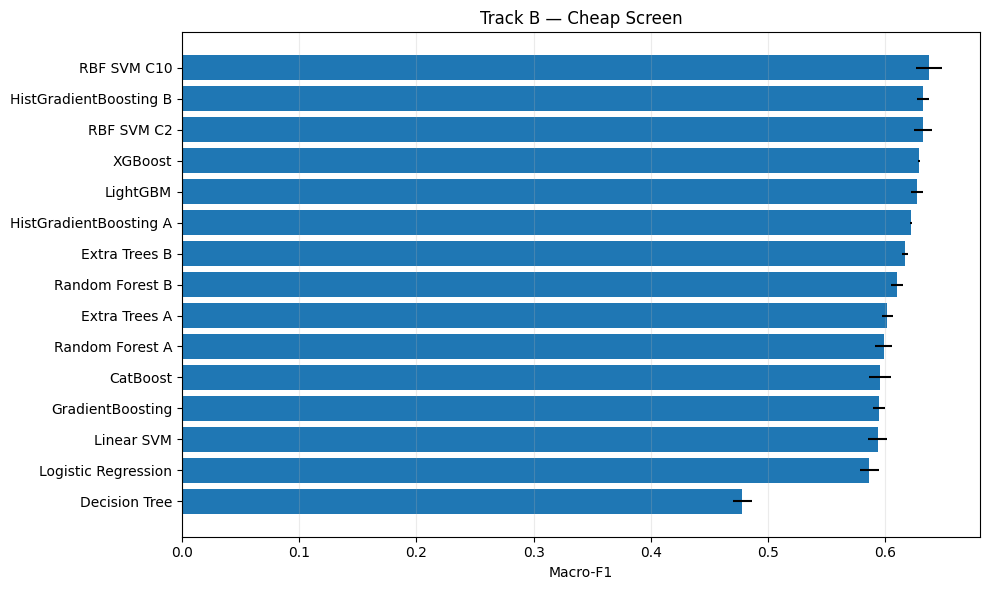

In [38]:
fig,ax=plt.subplots(figsize=(10,6))
screen_plot=successful_screen.sort_values("mean_macro_f1",ascending=True)
ax.barh(screen_plot["configuration"],screen_plot["mean_macro_f1"],xerr=screen_plot["sd_macro_f1"])
ax.set_xlabel("Macro-F1")
ax.set_title("Track B — Cheap Screen")
ax.grid(axis="x",alpha=0.25)
plt.tight_layout()
plt.show()

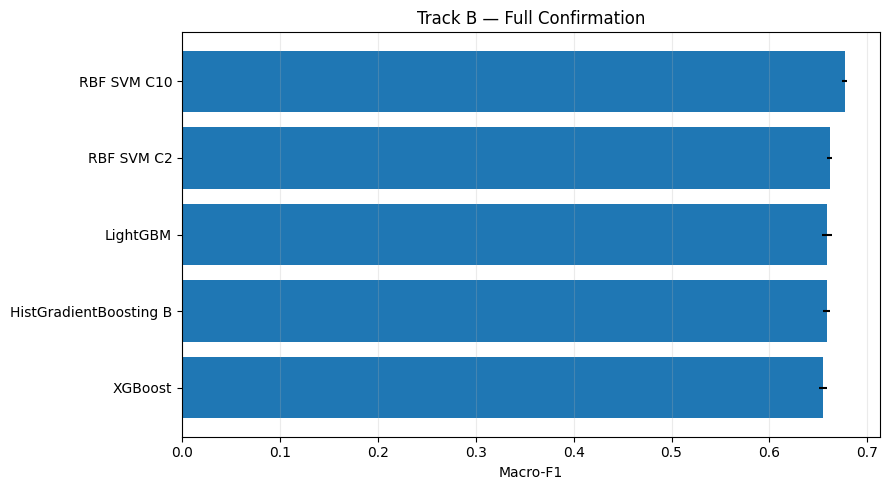

In [39]:
fig,ax=plt.subplots(figsize=(9,5))
confirm_plot=successful_confirmation.sort_values("mean_macro_f1",ascending=True)
ax.barh(confirm_plot["configuration"],confirm_plot["mean_macro_f1"],xerr=confirm_plot["sd_macro_f1"])
ax.set_xlabel("Macro-F1")
ax.set_title("Track B — Full Confirmation")
ax.grid(axis="x",alpha=0.25)
plt.tight_layout()
plt.show()

## 18. model selection stage handoff

Important outputs:

```text
track_b/
├── screen_results.csv
├── top_configs.csv
├── confirmation_results.csv
├── selected_model.json
├── development_confusion.csv
├── lockbox_result.csv
└── final_model.pkl
```

The final model comes from the **full five-fold confirmation stage**, not the cheap screen.

In [40]:
print("="*72)
print("TRACK B COMPLETE")
print("="*72)
print("Selected configuration:",SELECTED_CONFIGURATION)
print("Selected model:",SELECTED_MODEL)
print("Confirmation Macro-F1:",f"{SELECTED_MEAN:.6f} +/- {SELECTED_SD:.6f}")
if LOCKBOX_RESULT_PATH.exists():
    print("\nLockbox result:")
    display(pd.read_csv(LOCKBOX_RESULT_PATH))
print("\nTrack B output folder:",OUTPUT_DIR)
print("\nNext stage: Track C — Amsterdam few-shot adaptation.")

TRACK B COMPLETE
Selected configuration: RBF SVM C10
Selected model: RBF SVM
Confirmation Macro-F1: 0.676815 +/- 0.002176

Lockbox result:


,configuration,model,confirmation_mean_macro_f1,confirmation_sd_macro_f1,lockbox_macro_f1
0,RBF SVM C10,RBF SVM,0.676815,0.002176,0.675759



Track B output folder: /kaggle/working/track_b

Next stage: Track C — Amsterdam few-shot adaptation.
